# Phase 3 · Model 1 — ETA (delivery time) prediction

**Goal:** when an order is assigned to a robot, predict how many ticks it will take to deliver it.

**Data:** `data/processed/classical_ml/tasks.parquet` (dataset v3, one row per delivered order).

Workflow: 1 Understand → 2 Explore → 3 Target + features → 4 Split → 5 Preprocess → 6 Baseline →
7 Train → 8 Validate & tune → 9 Test once → 10 Save & report.

## Step 1 — Understand the problem

| Question | Answer |
|---|---|
| What do we predict? | `duration_ticks`: ticks from assignment to delivery at the packing station |
| When do we predict? | At the moment the order is assigned to a robot |
| Problem type | **Regression** (a number) |
| How do we judge it? | **MAE** (average error in ticks), **RMSE**, **R²**, compared with a simple baseline |

Rule that follows from "when": only information known **at assignment** may be used as input.

This cell imports the libraries and finds the project folders.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Find the project root (the folder that contains data/processed), wherever the notebook runs.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
DATA = ROOT / "data" / "processed" / "classical_ml"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 60)
print("Data folder:", DATA)

Data folder: H:\ai-warehouse-platform\data\processed\classical_ml


## Step 2 — Explore the data (EDA)

First look at the table: size, a few example rows.

In [2]:
df = pd.read_parquet(DATA / "tasks.parquet")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (161221, 45)


,dataset_version,run_id,date,day_index,day_of_week,day_name,is_weekend,week_of_year,month,season,is_promo_day,promo_name,split,order_id,robot_id,priority,n_items,n_units,order_time,assigned_at,sim_hour,delivered_at,queue_ticks,duration_ticks,late,start_x,start_y,station,battery_start,est_distance,path_distance,robot_speed,temperature_start,closures_active,floor_hazards_active,zone_congestion,fleet_busy,pending_orders,moves,waits,reroutes,total_weight_kg,main_category,categories,zones
0,v3,day_2026-09-07,2026-09-07,0,0,Monday,False,37,9,autumn,False,NaN,train,O00001,R15,MEDIUM,2,5,22,22,0,113,0,91,False,6,46,PACK_1,93.50,30,82,1.0,24.0,0,1,0.0,1,1,81,0,0,9.78,Toys & Games,Apparel|Toys & Games,ZONE_C
1,v3,day_2026-09-07,2026-09-07,0,0,Monday,False,37,9,autumn,False,NaN,train,O00002,R8,LOW,1,1,40,40,0,119,0,79,False,61,46,PACK_4,79.40,38,74,1.0,24.0,0,1,0.0,2,1,73,0,0,1.98,Toys & Games,Toys & Games,ZONE_D
2,v3,day_2026-09-07,2026-09-07,0,0,Monday,False,37,9,autumn,False,NaN,train,O00004,R8,HIGH,1,3,170,170,0,201,0,31,False,61,46,PACK_4,74.89,26,26,1.0,31.2,0,0,0.0,1,1,25,0,0,17.58,Grocery,Grocery,ZONE_D
3,v3,day_2026-09-07,2026-09-07,0,0,Monday,False,37,9,autumn,False,NaN,train,O00005,R37,HIGH,1,1,173,173,0,237,0,64,False,0,30,PACK_1,96.70,30,50,0.5,24.0,0,0,0.0,2,1,49,0,0,8.55,Grocery,Grocery,ZONE_C
4,v3,day_2026-09-07,2026-09-07,0,0,Monday,False,37,9,autumn,False,NaN,train,O00003,R36,HIGH,2,6,127,127,0,282,0,155,False,79,19,PACK_3,76.30,100,126,0.5,24.0,0,0,0.0,1,1,127,0,0,28.32,Home & Kitchen,Apparel|Home & Kitchen,ZONE_A|ZONE_B


Column types and missing values per column. Missing values must be handled before training.

In [3]:
pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()})

,dtype,missing
dataset_version,str,0
run_id,str,0
date,str,0
day_index,int64,0
day_of_week,int64,0
day_name,str,0
is_weekend,bool,0
week_of_year,int64,0
month,int64,0
season,str,0


Summary statistics: look for impossible values (negative times, battery above 100 %).

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
day_index,161221.0,47.106872,26.094761,0.00,25.00,49.00,70.00,90.00
day_of_week,161221.0,2.772685,1.913654,0.00,1.00,3.00,4.00,6.00
week_of_year,161221.0,43.333455,3.717455,37.00,40.00,44.00,47.00,49.00
month,161221.0,10.267285,0.900606,9.00,10.00,10.00,11.00,12.00
n_items,161221.0,1.497956,0.499997,1.00,1.00,1.00,2.00,2.00
n_units,161221.0,2.995001,1.417188,1.00,2.00,3.00,4.00,6.00
order_time,161221.0,7850.284671,3168.981717,1.00,5581.00,7898.00,10185.00,14346.00
assigned_at,161221.0,8046.619975,3283.155335,1.00,5627.00,8100.00,10627.00,14346.00
sim_hour,161221.0,12.915303,5.469199,0.00,9.00,13.00,17.00,23.00
delivered_at,161221.0,8217.379132,3291.430264,31.00,5805.00,8283.00,10804.00,14399.00


The **target**: its range and shape. A long right tail means some orders take much longer (traffic, faults, closed aisles).

count    161221.000000
mean        170.759157
std          80.676305
min          16.000000
25%         111.000000
50%         160.000000
75%         217.000000
max        1926.000000
Name: duration_ticks, dtype: float64


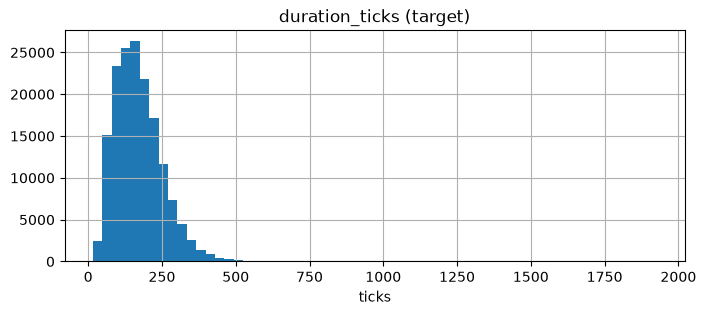

In [5]:
print(df["duration_ticks"].describe())
df["duration_ticks"].hist(bins=60, figsize=(8, 3))
plt.title("duration_ticks (target)")
plt.xlabel("ticks")
plt.show()

Which numeric columns move together with the target? Correlation shows the strongest single signals.

In [6]:
numeric = df.select_dtypes("number").columns
df[numeric].corrwith(df["duration_ticks"]).sort_values(ascending=False).round(3)

duration_ticks          1.000
moves                   0.950
path_distance           0.747
waits                   0.738
est_distance            0.719
reroutes                0.705
n_items                 0.446
fleet_busy              0.358
n_units                 0.314
start_y                 0.230
temperature_start       0.219
pending_orders          0.197
total_weight_kg         0.144
week_of_year            0.130
day_index               0.121
month                   0.115
delivered_at            0.115
queue_ticks             0.099
assigned_at             0.090
sim_hour                0.090
order_time              0.073
zone_congestion         0.061
closures_active        -0.001
floor_hazards_active   -0.003
start_x                -0.017
robot_speed            -0.046
day_of_week            -0.108
battery_start          -0.201
dtype: float64

`moves`, `waits` and `reroutes` correlate strongly — but they are only known **after** delivery.
Using them would be leakage (cheating). The next step removes them.

## Step 3 — Choose the target and the features

- **Target (y):** `duration_ticks`
- **Features (X):** only what is known at assignment (route distance, battery, temperature, speed,
  congestion, queue, closed aisles, order size, priority, category, time and calendar).
- **Excluded:** IDs, post-delivery columns (`moves`, `waits`, `reroutes`, `delivered_at`, `late`), raw dates.

The hour of the day is circular (23:00 is next to 00:00), so it is encoded as sine and cosine.

In [7]:
df["hour_sin"] = np.sin(2 * np.pi * df["sim_hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["sim_hour"] / 24)
for col in ["is_weekend", "is_promo_day"]:
    df[col] = df[col].astype(int)

NUMERIC = [
    "path_distance", "est_distance", "battery_start", "temperature_start", "robot_speed",
    "zone_congestion", "fleet_busy", "pending_orders", "queue_ticks", "closures_active",
    "floor_hazards_active", "n_items", "n_units", "total_weight_kg", "hour_sin", "hour_cos",
    "day_of_week", "is_weekend", "is_promo_day",
]  # fmt: skip
CATEGORICAL = ["priority", "main_category"]
LEAKS = ["moves", "waits", "reroutes", "delivered_at", "duration_ticks", "late"]
assert not set(LEAKS) & set(NUMERIC + CATEGORICAL), "a leak column is in the features!"
for col in CATEGORICAL:
    df[col] = df[col].astype(str)
TARGET = "duration_ticks"
print(len(NUMERIC), "numeric +", len(CATEGORICAL), "categorical features")

19 numeric + 2 categorical features


## Step 4 — Split

The `split` column was made **by date**: train = first 9 weeks, validation = next 2 weeks, test = last
2 weeks (includes Black Friday). We train on the past and test on the future, like real use.

In [8]:
train = df[df["split"] == "train"]
val = df[df["split"] == "validation"]
test = df[df["split"] == "test"]
for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:10s} {len(part):7,} rows  {part['date'].min()} .. {part['date'].max()}")

X_train, y_train = train[NUMERIC + CATEGORICAL], train[TARGET]
X_val, y_val = val[NUMERIC + CATEGORICAL], val[TARGET]
X_test, y_test = test[NUMERIC + CATEGORICAL], test[TARGET]

train      106,273 rows  2026-09-07 .. 2026-11-08
validation  27,266 rows  2026-11-09 .. 2026-11-22
test        27,682 rows  2026-11-23 .. 2026-12-06


## Step 5 — Preprocess

A `ColumnTransformer` scales numbers and one-hot encodes categories. Inside a pipeline it is
**fitted on train only** and applied unchanged to validation and test — nothing leaks.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
])
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## Step 6 — Baseline

Predict the average training duration for every order. Any real model must beat this.

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def scores(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
    }


baseline = scores(y_val, np.full(len(y_val), y_train.mean()))
print("Baseline (mean) on validation:", {k: round(v, 2) for k, v in baseline.items()})

Baseline (mean) on validation: {'MAE': 64.31, 'RMSE': 83.27, 'R2': -0.04}


## Step 7 — Train models

Four models from simple to strong: Linear Regression, Random Forest, Gradient Boosting (scikit-learn)
and **XGBoost** (the industry-standard gradient-boosting library). Each is a pipeline (preprocess +
model) trained on the train split and scored on validation.

In [11]:
import time

from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

candidates = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42
    ),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(
        n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8,
        colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=42,
    ),
}  # fmt: skip
results = {"Baseline (mean)": baseline}
for name, model in candidates.items():
    start = time.time()
    pipe = Pipeline([("prep", preprocess), ("model", model)]).fit(X_train, y_train)
    results[name] = scores(y_val, pipe.predict(X_val))
    print(f"{name:18s} trained in {time.time() - start:5.1f} s  val MAE {results[name]['MAE']:.2f}")
pd.DataFrame(results).T.round(2)

Linear Regression  trained in   0.7 s  val MAE 38.53


Random Forest      trained in  61.8 s  val MAE 38.76


Gradient Boosting  trained in   3.6 s  val MAE 38.04


XGBoost            trained in  11.1 s  val MAE 38.80


,MAE,RMSE,R2
Baseline (mean),64.31,83.27,-0.04
Linear Regression,38.53,52.98,0.58
Random Forest,38.76,53.00,0.58
Gradient Boosting,38.04,52.52,0.59
XGBoost,38.80,53.34,0.57


## Step 8 — Validate & tune

Both boosting libraries get a small grid of settings, judged **only on validation**; the best
combination overall becomes the final model. Then permutation importance shows which features it
relies on (how much worse it gets when a feature is shuffled).

In [12]:
def make(family, params):
    if family == "XGBoost":
        model = XGBRegressor(subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                             n_jobs=-1, random_state=42, **params)  # fmt: skip
    else:
        model = HistGradientBoostingRegressor(random_state=42, **params)
    return Pipeline([("prep", preprocess), ("model", model)])


grid = [("Gradient Boosting", {"learning_rate": lr, "min_samples_leaf": leaf, "max_iter": 300})
        for lr in (0.05, 0.1) for leaf in (20, 50)]  # fmt: skip
grid += [("XGBoost", {"learning_rate": lr, "max_depth": d, "n_estimators": 500})
         for lr in (0.05, 0.1) for d in (4, 6, 8)]  # fmt: skip
tuning = []
best_mae = float("inf")
for family, params in grid:
    pipe = make(family, params).fit(X_train, y_train)
    mae = mean_absolute_error(y_val, pipe.predict(X_val))
    tuning.append({"model": family, **params, "val_MAE": round(mae, 2)})
    if mae < best_mae:
        best_mae, best_family, best_params, best_model = mae, family, params, pipe
print("Best:", best_family, best_params, "val MAE", round(best_mae, 2))
pd.DataFrame(tuning).sort_values("val_MAE")

Best: Gradient Boosting {'learning_rate': 0.05, 'min_samples_leaf': 50, 'max_iter': 300} val MAE 38.0


,model,learning_rate,min_samples_leaf,max_iter,val_MAE,max_depth,n_estimators
0,Gradient Boosting,0.05,20.0,300.0,38.00,NaN,NaN
1,Gradient Boosting,0.05,50.0,300.0,38.00,NaN,NaN
2,Gradient Boosting,0.10,20.0,300.0,38.04,NaN,NaN
3,Gradient Boosting,0.10,50.0,300.0,38.10,NaN,NaN
4,XGBoost,0.05,NaN,NaN,38.61,4.0,500.0
5,XGBoost,0.05,NaN,NaN,38.96,6.0,500.0
7,XGBoost,0.10,NaN,NaN,39.04,4.0,500.0
6,XGBoost,0.05,NaN,NaN,39.07,8.0,500.0
8,XGBoost,0.10,NaN,NaN,39.27,6.0,500.0
9,XGBoost,0.10,NaN,NaN,39.83,8.0,500.0


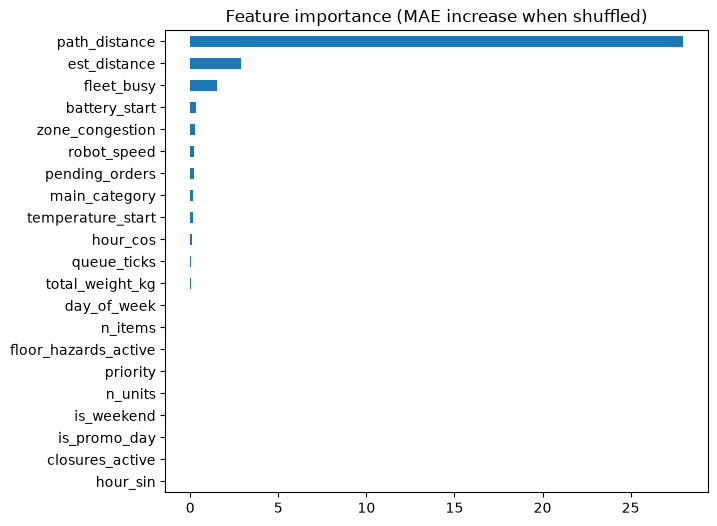

In [13]:
from sklearn.inspection import permutation_importance

sample = X_val.sample(5000, random_state=42)
imp = permutation_importance(
    best_model, sample, y_val.loc[sample.index], n_repeats=3, random_state=42,
    scoring="neg_mean_absolute_error",
)  # fmt: skip
importance = pd.Series(imp.importances_mean, index=sample.columns).sort_values()
importance.plot.barh(figsize=(7, 6), title="Feature importance (MAE increase when shuffled)")
plt.show()

## Step 9 — Test once

The tuned model is evaluated **one time** on the test split (the last 2 weeks, never seen before).
This is the honest score we report. We do not go back and tune after this.

TEST  model   : {'MAE': 38.82, 'RMSE': 55.33, 'R2': 0.56}
TEST  baseline: {'MAE': 65.36, 'RMSE': 85.69, 'R2': -0.05}
Improvement over baseline: 40.6 % lower MAE


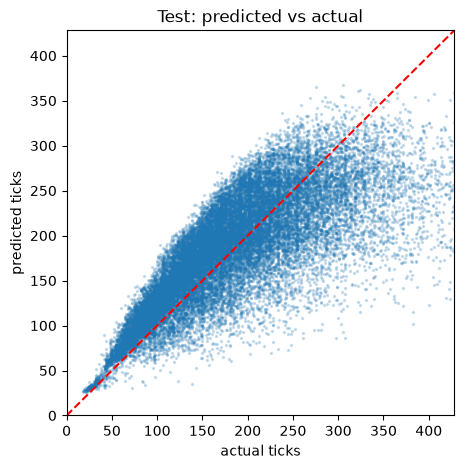

In [14]:
pred = best_model.predict(X_test)
test_scores = scores(y_test, pred)
test_baseline = scores(y_test, np.full(len(y_test), y_train.mean()))
print("TEST  model   :", {k: round(v, 2) for k, v in test_scores.items()})
print("TEST  baseline:", {k: round(v, 2) for k, v in test_baseline.items()})
gain = 100 * (1 - test_scores["MAE"] / test_baseline["MAE"])
print(f"Improvement over baseline: {gain:.1f} % lower MAE")

plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, s=2, alpha=0.2)
lim = [0, np.percentile(y_test, 99)]
plt.plot(lim, lim, "r--")
plt.xlim(lim)
plt.ylim(lim)
plt.xlabel("actual ticks")
plt.ylabel("predicted ticks")
plt.title("Test: predicted vs actual")
plt.show()

## Step 10 — Save & report

Save the full pipeline (preprocessing + model) for the backend, plus a report with every score.

In [15]:
joblib.dump(best_model, MODELS / "eta_v1.joblib")
report = {
    "model": "eta_v1",
    "algorithm": best_family,
    "params": best_params,
    "target": TARGET,
    "features": NUMERIC + CATEGORICAL,
    "dataset_version": "v3",
    "validation": {n: {k: round(v, 3) for k, v in s.items()} for n, s in results.items()},
    "tuning": tuning,
    "test": {k: round(v, 3) for k, v in test_scores.items()},
    "test_baseline": {k: round(v, 3) for k, v in test_baseline.items()},
}
(MODELS / "eta_v1_report.json").write_text(json.dumps(report, indent=2))
print("Saved models/eta_v1.joblib and models/eta_v1_report.json")
pd.DataFrame({"model": test_scores, "baseline": test_baseline}).round(2)

Saved models/eta_v1.joblib and models/eta_v1_report.json


,model,baseline
MAE,38.82,65.36
RMSE,55.33,85.69
R2,0.56,-0.05


## Summary

**What we predict:** how many ticks an order will take from the moment a robot is assigned until it
is delivered at the packing station (ETA, a regression problem).

**Before (without this model):** no delivery-time estimate. The best guess was the average time — the
baseline — wrong by **65.4 ticks** on average and explaining nothing (R² -0.04).

**Models compared on validation** (before tuning):

| Model | val MAE (ticks) | val R² |
|---|---|---|
| Baseline (mean) | 64.3 | -0.04 |
| Linear Regression | 38.5 | 0.58 |
| Random Forest | 38.8 | 0.58 |
| Gradient Boosting | 38.0 | 0.59 |
| XGBoost | 38.8 | 0.57 |

**Final model:** Gradient Boosting (tuned), chosen on validation.

| Test set (last 2 weeks, never seen) | MAE (ticks) | RMSE (ticks) | R² |
|---|---|---|---|
| Baseline: average time | 65.4 | 85.7 | -0.04 |
| **Gradient Boosting (eta_v1)** | **38.8** | **55.3** | **0.56** |

**What it shows**
- Delivery time can be predicted in advance: **41 % lower error** than the average guess.
- The tree ensembles (Random Forest, Gradient Boosting, XGBoost) end up very close to each other: the
  limit is the information available at assignment, not the algorithm.
- The remaining error comes from events after assignment (traffic jams, faults) that nobody can know in
  advance. No leakage: `moves`, `waits`, `reroutes` excluded; split by date; test used once.

**How it is used:** the backend predicts an ETA for every assigned order (dashboard, Orders page) and
saves each prediction with the real delivery time in the `predictions` table. In Phase 4 the
dispatcher will give each order to the robot predicted to finish first.

**Saved:** `models/eta_v1.joblib`, `models/eta_v1_report.json`.